# Experiment: XAUUSD ML Bull / ML Bear v0.3 (calendar + market + session)

**คำถาม:** เพิ่ม feature ข่าว (economic calendar, VIX, DXY, US10Y, session) และขยายช่วงเทรนไปทั้งปี 2024 แล้ว โมเดลจะดีขึ้นไหม?

**เกณฑ์ความสำเร็จ:** AUC เฉลี่ยข้าม fold (bull+bear) ดีกว่า v0.2 E3 baseline (0.595 intraday) และ nested trading expectancy เป็นบวก

| | v0.2 | v0.3 |
|---|---|---|
| ช่วงเทรน | 2025-01 → 2026-01 (1 ปี) | **2024-01 → 2026-01 (2 ปี)** |
| feature ใหม่ | ไม่มี | **ข่าว (NFP/FOMC/CPI), VIX, DXY, US10Y, session** |
| walk-forward | เม.ย. 2025 → ม.ค. 2026 (10 เดือน) | **เม.ย. 2024 → ม.ค. 2026 (22 เดือน)** |
| การทดลอง | E0–E5 (model type + feature set) | **F0–F5 (ข่าว/ตลาด/session)** |

แนวคิด: ML ทำได้ดีด้าน regime (atr_regime, adx14, hour) แต่จับข่าว/event ไม่ได้ → เพิ่ม feature ที่บอกว่า "วันนี้มีข่าวสำคัญไหม" และ "ตลาดกลัวแค่ไหน" โดยไม่ต้องเรียก LLM

In [1]:
# Setup: imports and reproducibility
from __future__ import annotations

import dataclasses
import hashlib
import json
import sys
import warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, roc_auc_score

NB_DIR = Path.cwd()
assert (NB_DIR / "xau_ml").is_dir(), "Open notebook from Product/notebook/"
sys.path.insert(0, str(NB_DIR))
from xau_ml import config as C  # noqa: E402
from xau_ml import cv as CV  # noqa: E402
from xau_ml import data as D  # noqa: E402
from xau_ml import features as F  # noqa: E402
from xau_ml import labels as L  # noqa: E402
from xau_ml import sim as S  # noqa: E402
from xau_ml import v3 as V  # noqa: E402
from xau_ml.calendar import CALENDAR_COLS  # noqa: E402
from xau_ml.market_data import MARKET_COLS  # noqa: E402
from xau_ml.model import Calibrator  # noqa: E402

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 40, "display.float_format", "{:.4f}".format)
SIDES = ("bull", "bear")
LS = C.LABEL_SETS["ct25"]
print(f"version {C.VERSION_V3} | label set {LS.name} | train from {C.V3_TRAIN_FROM}")

version xau-bullbear-0.3.0 | label set ct25 | train from 2024-01-01


## 1. ข้อมูล + feature + label

ขยายช่วงเทรนไป 2024-01 เพื่อให้โมเดลเห็น regime ที่หลากหลายกว่า รวมถึง noise และแท่งผิดปกติ เพิ่ม feature ข่าว (calendar) และตลาด (VIX/DXY/US10Y)

In [2]:
# Load bars with extended warm-up for 2024 training
RAW = {tf: D.load(tf, C.V3_WARMUP_START[tf]) for tf in ("15m", "1h", "1d")}
for tf, df in RAW.items():
    print(f"{tf}: {len(df):,} bars, {df['date'].min()} to {df['date'].max()}")

15m: 52,379 bars, 2023-10-02 01:00:00 to 2026-01-30 23:45:00
1h: 15,105 bars, 2023-06-01 01:00:00 to 2026-01-30 23:00:00
1d: 661 bars, 2023-06-01 00:00:00 to 2026-01-30 00:00:00


In [3]:
# Build features: base (v0.2) + extras + calendar + market
FR, COLS = {}, {}
for hz in C.HORIZONS.values():
    base = F.build(RAW[hz.tf], hz.tf, {tf: RAW[tf] for tf in hz.htf})
    base = F.add_extras(base, RAW["1d"])  # v0.2 extras (levels, session)
    base = V.add_v3_features(base)         # v0.3: calendar + market
    FR[hz.name] = L.add_labels(base, hz, LS)
    COLS[hz.name] = F.feature_columns(FR[hz.name])
    # Ensure new columns are present
    for c in CALENDAR_COLS + MARKET_COLS:
        assert c in FR[hz.name].columns, f"Missing {c} in {hz.name}"
    st = FR[hz.name].query("date >= @C.V3_TRAIN_FROM")
    print(f"{hz.name}: {len(COLS[hz.name])} features ({len(CALENDAR_COLS)} calendar + {len(MARKET_COLS)} market) | "
          f"usable rows from 2024: {int(CV.usable(st).sum()):,} | "
          f"long wins {st['y_bull'].mean():.3f} short wins {st['y_bear'].mean():.3f}")

intraday: 77 features (6 calendar + 11 market) | usable rows from 2024: 46,066 | long wins 0.321 short wins 0.181


swing: 68 features (6 calendar + 11 market) | usable rows from 2024: 11,201 | long wins 0.453 short wins 0.212


In [4]:
# Inspect calendar features on sample bars
sample = FR["intraday"][
    FR["intraday"]["cal_high_today"] == 1
].groupby(FR["intraday"]["date"].dt.normalize()).first().head(10)
display(sample[["date", "cal_high_today", "cal_event_count", "cal_is_nfp_day",
                "cal_is_fomc_day", "cal_hours_to_next", "cal_hours_since_last"]].round(2))
print(f"\nEvent days in training data: {int(FR['intraday'].query('date >= @C.V3_TRAIN_FROM')['cal_high_today'].sum()):,} bars")
print(f"NFP days: {int(FR['intraday'].query('date >= @C.V3_TRAIN_FROM')['cal_is_nfp_day'].sum()):,} bars")
print(f"FOMC days: {int(FR['intraday'].query('date >= @C.V3_TRAIN_FROM')['cal_is_fomc_day'].sum()):,} bars")

,date,cal_high_today,cal_event_count,cal_is_nfp_day,cal_is_fomc_day,cal_hours_to_next,cal_hours_since_last
date,,,,,,,
2023-10-06,2023-10-06 01:00:00,1.0000,1.0000,1.0000,0.0000,14.5000,48.0000
2023-11-03,2023-11-03 00:00:00,1.0000,1.0000,1.0000,0.0000,15.5000,48.0000
2023-12-01,2023-12-01 01:00:00,1.0000,1.0000,1.0000,0.0000,14.5000,48.0000
2024-01-05,2024-01-05 01:00:00,1.0000,1.0000,1.0000,0.0000,14.5000,48.0000
2024-01-11,2024-01-11 01:00:00,1.0000,1.0000,0.0000,0.0000,14.5000,48.0000
2024-01-31,2024-01-31 01:00:00,1.0000,1.0000,0.0000,1.0000,20.0000,48.0000
2024-02-02,2024-02-02 01:00:00,1.0000,1.0000,1.0000,0.0000,14.5000,28.0000
2024-02-13,2024-02-13 01:00:00,1.0000,1.0000,0.0000,0.0000,14.5000,48.0000
2024-03-01,2024-03-01 01:00:00,1.0000,1.0000,1.0000,0.0000,14.5000,48.0000



Event days in training data: 5,717 bars
NFP days: 2,167 bars
FOMC days: 1,472 bars


In [5]:
# Inspect market features
sample_market = FR["intraday"].query("date >= @C.V3_TRAIN_FROM")[
    ["date", "vix", "vix_ret_5", "vix_level", "dxy", "dxy_ret_5", "us10y", "us10y_chg_5"]
].dropna().iloc[::2000]
display(sample_market.round(4))

# NaN coverage
for c in MARKET_COLS:
    if c in FR["intraday"].columns:
        pct = FR["intraday"].query("date >= @C.V3_TRAIN_FROM")[c].isna().mean()
        if pct > 0:
            print(f"  {c}: {pct:.1%} NaN (LightGBM handles natively)")

,date,vix,vix_ret_5,vix_level,dxy,dxy_ret_5,us10y,us10y_chg_5
5862,2024-01-02 01:00:00,12.4500,-0.0879,0.9789,101.3300,-0.0050,3.8660,-0.0280
7862,2024-01-31 20:15:00,13.3100,0.0606,0.9972,103.4000,-0.0021,4.0590,-0.0830
9862,2024-03-01 16:45:00,13.4000,-0.0784,0.9610,104.1600,0.0019,4.2520,-0.0750
11862,2024-04-03 10:45:00,14.6100,0.1077,1.0533,104.8200,0.0057,4.3650,0.1120
13862,2024-05-03 04:45:00,14.6800,-0.0449,0.9002,105.3000,-0.0028,4.5710,-0.1350
15862,2024-06-04 01:15:00,13.1100,0.0989,1.0181,104.1400,-0.0055,4.4020,-0.0650
17862,2024-07-03 20:45:00,12.0300,-0.0631,0.9548,105.7200,0.0010,4.4360,0.1980
19862,2024-08-02 17:00:00,18.5900,0.0070,1.2369,104.4200,0.0006,3.9760,-0.2800
21862,2024-09-03 13:30:00,15.0000,-0.0542,0.7835,101.7000,0.0097,3.9110,0.1040
23862,2024-10-03 07:30:00,18.9000,0.2265,1.0754,101.6800,0.0075,3.7850,0.0040


In [6]:
# Look-ahead test: verify all new features are known at bar close
rng = np.random.default_rng(SEED)
for hz in C.HORIZONS.values():
    fr = FR[hz.name]
    cols_to_check = [c for c in COLS[hz.name] if c in CALENDAR_COLS]
    # Calendar features are deterministic from the date — no truncation test needed,
    # but verify they don't reference future dates
    for c in cols_to_check:
        assert not fr[c].isna().all(), f"{hz.name}/{c} is all NaN"
    # Market features: verify backward merge (t_close based)
    for tc in F.TIME_COLS:
        if tc in fr:
            assert (fr[tc].isna() | (fr[tc] <= fr["t_close"])).all(), tc
    print(f"{hz.name}: look-ahead checks passed \u2713")

intraday: look-ahead checks passed ✓
swing: look-ahead checks passed ✓


## 2. Protocol: expanding walk-forward รายเดือน (เม.ย. 2024 → ม.ค. 2026)

- fold = เดือนปฏิทิน เม.ย. 2024 → ม.ค. 2026 (22 เดือน) · train = ทุกแถวตั้งแต่ 2024-01 จนถึงก่อนเดือนนั้น
- nested: เหมือน v0.2 — calibrator + τ/m จาก OOF ของเดือนก่อน k เท่านั้น
- เม.ย.–พ.ค. 2024 เป็น burn-in (ใช้เลือก τ/m ไม่นับผลเทรด) · ทดลองจริงเริ่ม มิ.ย. 2024

In [7]:
FOLDS = {}
rows = []
for hz in C.HORIZONS.values():
    folds = CV.monthly_folds(FR[hz.name], hz, C.V3_WF_FIRST_FOLD, C.V3_WF_LAST_FOLD, C.V3_TRAIN_FROM)
    CV.assert_folds(FR[hz.name], folds, hz)
    FOLDS[hz.name] = folds
    for f in folds:
        rows.append({"horizon": hz.name, "fold": f.name, "train_rows": len(f.train),
                     "test_rows": len(f.test),
                     "train_to": FR[hz.name]["date"].iloc[f.train].max(),
                     "test_from": FR[hz.name]["date"].iloc[f.test].min()})
print(f"purge/embargo: no training label reaches its test month \u2713")
print(f"v0.3: {len(FOLDS['intraday'])} intraday folds, {len(FOLDS['swing'])} swing folds")
display(pd.DataFrame(rows).pivot_table(index="fold", columns="horizon",
                                        values=["train_rows", "test_rows"]))

purge/embargo: no training label reaches its test month ✓
v0.3: 22 intraday folds, 22 swing folds


test_rows          train_rows           
horizon  intraday    swing   intraday      swing
fold                                            
2024-04 2008.0000 458.0000  5760.0000  1396.0000
2024-05 2090.0000 479.0000  7784.0000  1902.0000
2024-06 1814.0000 410.0000  9890.0000  2429.0000
2024-07 2091.0000 479.0000 11720.0000  2887.0000
2024-08 2008.0000 458.0000 13827.0000  3414.0000
2024-09 1906.0000 433.0000 15851.0000  3920.0000
2024-10 2100.0000 481.0000 17773.0000  4401.0000
2024-11 1897.0000 431.0000 19889.0000  4930.0000
2024-12 1903.0000 432.0000 21802.0000  5409.0000
2025-01 1984.0000 454.0000 23721.0000  5889.0000
2025-02 1814.0000 410.0000 25721.0000  6391.0000
2025-03 1916.0000 435.0000 27551.0000  6849.0000
2025-04 1916.0000 435.0000 29483.0000  7332.0000
2025-05 1993.0000 456.0000 31415.0000  7815.0000
2025-06 1906.0000 433.0000 33424.0000  8319.0000
2025-07 2024.0000 464.0000 35346.0000  8800.0000
2025-08 1916.0000 435.0000 37386.0000  9312.0000
2025-09  877.0000 131.0000 39318.0000  9795.0000
2025-10  969.0000  93.0000 40228.0000 10023.0000
2025-11 1805.0000 408.0000 41180.0000 10067.0000
2025-12 1995.0000 455.0000 43001.0000 10523.0000
2026-01 1021.0000  78.0000 45012.0000 11026.0000

## 3. การทดลอง F0–F5

| ID | ชื่อ | features |
|---|---|---|
| F0 | v0.2 E3 baseline (reduced 20) | atr_regime, atr_pct, rv_32, bb_width, adx14, hour, dow + d1_* |
| F1 | + session | F0 + session (asia/london/ny) |
| F2 | + calendar | F0 + NFP/FOMC/CPI/hours_to/since |
| F3 | + market | F0 + VIX/DXY/US10Y |
| F4 | + calendar + market + session | F0 + ทุกอย่าง |
| F5 | full + all new | ทุก feature + calendar + market |

**กฎเลือก:** AUC เฉลี่ยข้าม fold (bull+bear) สูงสุด — ไม่ใช้ผลเทรดในการเลือก

In [8]:
# List feature columns per experiment
for exp in V.EXPERIMENTS:
    cols = V.columns(exp, COLS["intraday"])
    new_cols = [c for c in cols if c in CALENDAR_COLS + MARKET_COLS + ["session"]]
    print(f"{exp.id}: {len(cols)} features ({len(new_cols)} new: {new_cols[:5]}{'...' if len(new_cols) > 5 else ''})")

F0: 20 features (0 new: [])
F1: 21 features (1 new: ['session'])
F2: 26 features (6 new: ['cal_high_today', 'cal_event_count', 'cal_is_nfp_day', 'cal_is_fomc_day', 'cal_hours_to_next']...)
F3: 31 features (11 new: ['vix', 'vix_ret_5', 'vix_dist_sma20', 'vix_level', 'dxy']...)
F4: 38 features (18 new: ['session', 'cal_high_today', 'cal_event_count', 'cal_is_nfp_day', 'cal_is_fomc_day']...)
F5: 71 features (18 new: ['session', 'cal_high_today', 'cal_event_count', 'cal_is_nfp_day', 'cal_is_fomc_day']...)


In [9]:
# Run all experiments
OOF, FOLD_ML, ml_rows = {}, {}, []
for hz in C.HORIZONS.values():
    for exp in V.EXPERIMENTS:
        cols = V.columns(exp, COLS[hz.name])
        oof, per_fold = V.run_oof(exp, FR[hz.name], FOLDS[hz.name], cols, hz)
        OOF[(hz.name, exp.id)], FOLD_ML[(hz.name, exp.id)] = oof, per_fold
        ml_rows.append({
            "horizon": hz.name, "exp": exp.id, "name": exp.name,
            "features": len(cols),
            "auc_bull": per_fold["auc_bull"].mean(),
            "auc_bear": per_fold["auc_bear"].mean(),
            "auc_mean": per_fold[["auc_bull", "auc_bear"]].mean(axis=1).mean(),
            "auc_bull_min_fold": per_fold["auc_bull"].min(),
            "auc_bear_min_fold": per_fold["auc_bear"].min(),
            "logloss_gain_bull": (per_fold["logloss_clim_bull"] - per_fold["logloss_bull"]).mean(),
            "logloss_gain_bear": (per_fold["logloss_clim_bear"] - per_fold["logloss_bear"]).mean(),
        })
        print(f"  {hz.name}/{exp.id}: AUC bull={per_fold['auc_bull'].mean():.4f} bear={per_fold['auc_bear'].mean():.4f}")
ML_TABLE = pd.DataFrame(ml_rows)
display(ML_TABLE)

  intraday/F0: AUC bull=0.5808 bear=0.6334


  intraday/F1: AUC bull=0.5819 bear=0.6287


  intraday/F2: AUC bull=0.5859 bear=0.6305


  intraday/F3: AUC bull=0.5895 bear=0.6364


  intraday/F4: AUC bull=0.5871 bear=0.6303


...

  swing/F2: AUC bull=0.5681 bear=0.5345


  swing/F3: AUC bull=0.5964 bear=0.5996


  swing/F4: AUC bull=0.5886 bear=0.6269


  swing/F5: AUC bull=0.5849 bear=0.6023


,horizon,exp,name,features,auc_bull,auc_bear,auc_mean,auc_bull_min_fold,auc_bear_min_fold,logloss_gain_bull,logloss_gain_bear
0,intraday,F0,"v0.2 E3 baseline (reduced 20, weights)",20,0.5808,0.6334,0.6071,0.4841,0.5389,0.0085,0.0126
1,intraday,F1,v0.2 E3 + session,21,0.5819,0.6287,0.6053,0.4505,0.4980,0.0075,0.0107
2,intraday,F2,v0.2 E3 + calendar features,26,0.5859,0.6305,0.6082,0.4862,0.5070,0.0083,0.0115
3,intraday,F3,v0.2 E3 + market features (VIX/DXY/US10Y),31,0.5895,0.6364,0.6130,0.4508,0.5859,0.0091,0.0122
4,intraday,F4,v0.2 E3 + calendar + market + session,38,0.5871,0.6303,0.6087,0.4880,0.5254,0.0078,0.0109
5,intraday,F5,full features + calendar + market + session,71,0.5766,0.6313,0.6039,0.4672,0.5715,0.0078,0.0112
6,swing,F0,"v0.2 E3 baseline (reduced 20, weights)",20,0.5474,0.5424,0.5449,0.3829,0.2309,-0.0015,-0.0082
7,swing,F1,v0.2 E3 + session,21,0.5472,0.5118,0.5295,0.3356,0.2331,-0.0060,-0.0063
8,swing,F2,v0.2 E3 + calendar features,26,0.5681,0.5345,0.5513,0.3316,0.1926,0.0011,-0.0061
9,swing,F3,v0.2 E3 + market features (VIX/DXY/US10Y),31,0.5964,0.5996,0.5980,0.3921,0.2416,-0.0037,-0.0054


## 4. เลือกการทดลองที่ดีที่สุด + nested trading

In [10]:
CHOSEN = {}
for hz in C.HORIZONS.values():
    t = ML_TABLE[ML_TABLE["horizon"] == hz.name].sort_values("auc_mean", ascending=False)
    CHOSEN[hz.name] = next(e for e in V.EXPERIMENTS if e.id == t.iloc[0]["exp"])
    print(f"{hz.name}: chosen {CHOSEN[hz.name].id} \u2014 {CHOSEN[hz.name].name} "
          f"(mean fold AUC {t.iloc[0]['auc_mean']:.4f}; "
          f"runner-up {t.iloc[1]['exp']} {t.iloc[1]['auc_mean']:.4f})")

intraday: chosen F3 — v0.2 E3 + market features (VIX/DXY/US10Y) (mean fold AUC 0.6130; runner-up F4 0.6087)
swing: chosen F4 — v0.2 E3 + calendar + market + session (mean fold AUC 0.6078; runner-up F3 0.5980)


In [11]:
# Nested out-of-sample trading for every experiment + baselines
TRADE, TRADES, NEST = [], {}, {}
for hz in C.HORIZONS.values():
    fr, names = FR[hz.name], [f.name for f in FOLDS[hz.name]]
    for exp in V.EXPERIMENTS:
        trades, log, cal, sig, scored = V.nested_trading(
            fr, OOF[(hz.name, exp.id)], names, C.V3_WF_BURN_IN, C.MIN_VAL_TRADES[hz.tf])
        TRADES[(hz.name, exp.id)], NEST[(hz.name, exp.id)] = trades, (log, cal, sig, scored)
        TRADE.append({"horizon": hz.name, "strategy": exp.id, **S.metrics(trades)})
    oof0 = OOF[(hz.name, "F0")]
    scored_pos = oof0["pos"].to_numpy()[oof0["fold"].isin(names[C.V3_WF_BURN_IN:]).to_numpy()]
    for kind in ("always_long", "always_short", "sma20_50_cross"):
        t = V.baseline_trades(fr, scored_pos, kind)
        TRADES[(hz.name, kind)] = t
        TRADE.append({"horizon": hz.name, "strategy": kind, **S.metrics(t)})

TRADE = pd.DataFrame(TRADE)
# Bootstrap CI
for i, r in TRADE.iterrows():
    t = TRADES[(r["horizon"], r["strategy"])]
    lo, hi = CV.bootstrap_mean_ci(t["r"].to_numpy()) if len(t) else (np.nan, np.nan)
    dlo, dhi = CV.bootstrap_diff_ci(
        t["r"].to_numpy(), TRADES[(r["horizon"], "always_long")]["r"].to_numpy()
    ) if len(t) else (np.nan, np.nan)
    TRADE.loc[i, ["exp_ci90_lo", "exp_ci90_hi", "vs_long_ci90_lo", "vs_long_ci90_hi"]] = [lo, hi, dlo, dhi]
TRADE["beats_always_long"] = TRADE["vs_long_ci90_lo"] > 0

display(TRADE[["horizon", "strategy", "trades", "win_rate", "profit_factor",
               "expectancy_r", "exp_ci90_lo", "exp_ci90_hi",
               "vs_long_ci90_lo", "vs_long_ci90_hi", "beats_always_long",
               "max_dd_pct", "long_share"]])

,horizon,strategy,trades,win_rate,profit_factor,expectancy_r,exp_ci90_lo,exp_ci90_hi,vs_long_ci90_lo,vs_long_ci90_hi,beats_always_long,max_dd_pct,long_share
0,intraday,F0,419,0.4678,1.1054,0.0588,-0.0389,0.1560,-0.0443,0.1583,False,20.4402,0.9928
1,intraday,F1,660,0.4455,1.0218,0.0126,-0.0639,0.0884,-0.0706,0.0923,False,30.7139,1.0000
2,intraday,F2,627,0.4657,1.1071,0.0594,-0.0233,0.1391,-0.0290,0.1418,False,23.9299,0.9920
3,intraday,F3,1748,0.4485,1.0337,0.0189,-0.0283,0.0642,-0.0382,0.0713,False,30.9906,0.9989
4,intraday,F4,886,0.4413,1.0026,0.0015,-0.0616,0.0673,-0.0693,0.0703,False,35.1441,0.9977
5,intraday,F5,1078,0.4453,1.0400,0.0228,-0.0383,0.0821,-0.0449,0.0889,False,30.2143,0.9963
6,intraday,always_long,4734,0.4438,1.0028,0.0015,-0.0261,0.0294,-0.0386,0.0386,False,61.5887,1.0000
7,intraday,always_short,4051,0.3436,0.8003,-0.1276,-0.1609,-0.0932,-0.1723,-0.0851,False,99.6447,0.0000
8,intraday,sma20_50_cross,757,0.4122,0.9907,-0.0052,-0.0767,0.0668,-0.0830,0.0705,False,45.8036,0.4914
9,swing,F0,386,0.5000,1.4438,0.2217,0.1179,0.3254,-0.0881,0.1842,False,11.7168,1.0000


In [12]:
# Per-fold detail for chosen experiments
for hzn, exp in CHOSEN.items():
    key = (hzn, exp.id)
    log, cal, sig, scored = NEST[key]
    per = FOLD_ML[key][["fold", "train_rows", "test_rows", "auc_bull", "auc_bear"]].merge(
        log, on="fold", how="left")
    t = TRADES[key]
    if len(t):
        by_month = t.groupby(
            pd.to_datetime(t["entry"]).dt.to_period("M").astype(str)
        ).agg(trades=("r", "size"), total_r=("r", "sum"),
              long=("side", lambda s: (s == "long").mean()))
        per = per.merge(by_month, left_on="fold", right_index=True, how="left")
    print(f"\n{hzn} / {exp.id}: per-fold AUC, nested tau/m and trades")
    display(per)


intraday / F3: per-fold AUC, nested tau/m and trades


,fold,train_rows,test_rows,auc_bull,auc_bear,tau,m,trades_prior_at_choice,signals,long_signals,trades,total_r,long
0,2024-04,5760,2008,0.5510,0.6384,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-05,7784,2090,0.5683,0.7188,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-06,9890,1814,0.6322,0.6205,0.3000,0.1500,141.0000,1126.0000,1126.0000,183.0000,4.6830,1.0000
3,2024-07,11720,2091,0.6626,0.5882,0.4000,0.2000,41.0000,151.0000,151.0000,27.0000,5.4992,1.0000
4,2024-08,13827,2008,0.6578,0.6334,0.4000,0.2000,40.0000,2.0000,2.0000,1.0000,-1.1070,1.0000
5,2024-09,15851,1906,0.6272,0.6480,0.4000,0.2000,109.0000,269.0000,269.0000,52.0000,-7.7261,1.0000
6,2024-10,17773,2100,0.6190,0.6288,0.3250,0.0000,888.0000,1290.0000,1290.0000,201.0000,6.7410,1.0000
7,2024-11,19889,1897,0.6850,0.5869,0.3250,0.2000,671.0000,1051.0000,1051.0000,160.0000,14.6268,1.0000
8,2024-12,21802,1903,0.5204,0.5903,0.4500,0.0000,125.0000,913.0000,913.0000,129.0000,-13.5018,1.0000
9,2025-01,23721,1984,0.6441,0.6766,0.3750,0.1000,548.0000,220.0000,220.0000,31.0000,1.4888,1.0000



swing / F4: per-fold AUC, nested tau/m and trades


,fold,train_rows,test_rows,auc_bull,auc_bear,tau,m,trades_prior_at_choice,signals,long_signals,trades,total_r,long
0,2024-04,1396,458,0.4998,0.7227,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-05,1902,479,0.4286,0.4028,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-06,2429,410,0.5142,0.6232,0.3750,0.2000,55.0000,282.0000,282.0000,23.0000,1.1129,1.0000
3,2024-07,2887,479,0.5186,0.3475,0.4000,0.2000,51.0000,70.0000,70.0000,8.0000,-1.8671,1.0000
4,2024-08,3414,458,0.5974,0.7470,0.5000,0.0000,22.0000,415.0000,415.0000,30.0000,0.1375,1.0000
5,2024-09,3920,433,0.3465,0.5616,0.4000,0.0000,168.0000,433.0000,433.0000,30.0000,11.7957,1.0000
6,2024-10,4401,481,0.4342,0.5088,0.3750,0.0000,198.0000,481.0000,481.0000,35.0000,10.3106,1.0000
7,2024-11,4930,431,0.6356,0.6240,0.5000,0.0000,99.0000,46.0000,46.0000,8.0000,-3.1244,1.0000
8,2024-12,5409,432,0.5709,0.6810,0.4000,0.0000,266.0000,379.0000,379.0000,26.0000,-4.0815,1.0000
9,2025-01,5889,454,0.5855,0.7226,0.3500,0.0000,294.0000,454.0000,454.0000,35.0000,11.5812,1.0000


## 5. เปรียบเทียบ v0.3 vs v0.2: ช่วงที่ไม่เคยเห็น vs เคยเห็น

In [13]:
# Split results by period: 2024 (new data) vs 2025+ (overlap with v0.2)
rows = []
for hzn, exp in CHOSEN.items():
    for name in (exp.id, "F0", "always_long", "always_short"):
        t = TRADES[(hzn, name)]
        if t.empty:
            continue
        for part, m in (
            ("2024 (new)", pd.to_datetime(t["entry"]) < "2025-01-01"),
            ("2025-H1", pd.to_datetime(t["entry"]).between("2025-01-01", "2025-06-30")),
            ("2025-H2+", pd.to_datetime(t["entry"]) >= "2025-07-01"),
        ):
            sub = t[m.to_numpy()]
            if sub.empty:
                continue
            rows.append({"horizon": hzn, "strategy": name, "period": part,
                         **S.metrics(sub.assign(equity=np.cumprod(1 + C.RISK_PCT * sub["r"].to_numpy())))})

period_df = pd.DataFrame(rows)
display(period_df[["horizon", "strategy", "period", "trades", "win_rate",
                    "profit_factor", "expectancy_r", "long_share"]])

,horizon,strategy,period,trades,win_rate,profit_factor,expectancy_r,long_share
0,intraday,F3,2024 (new),753,0.4475,1.0212,0.0122,1.0000
1,intraday,F3,2025-H1,715,0.4392,1.0056,0.0032,1.0000
2,intraday,F3,2025-H2+,276,0.4710,1.1312,0.0658,0.9928
3,intraday,F0,2024 (new),334,0.4611,1.0743,0.0420,1.0000
4,intraday,F0,2025-H1,50,0.5600,1.6033,0.2824,1.0000
5,intraday,F0,2025-H2+,35,0.4000,0.8334,-0.1010,0.9143
6,intraday,always_long,2024 (new),1837,0.4453,0.9837,-0.0091,1.0000
7,intraday,always_long,2025-H1,1543,0.4420,0.9998,-0.0001,1.0000
8,intraday,always_long,2025-H2+,1344,0.4420,1.0239,0.0129,1.0000
9,intraday,always_short,2024 (new),1629,0.3407,0.7715,-0.1485,0.0000


## 6. Calibration + cumulative R

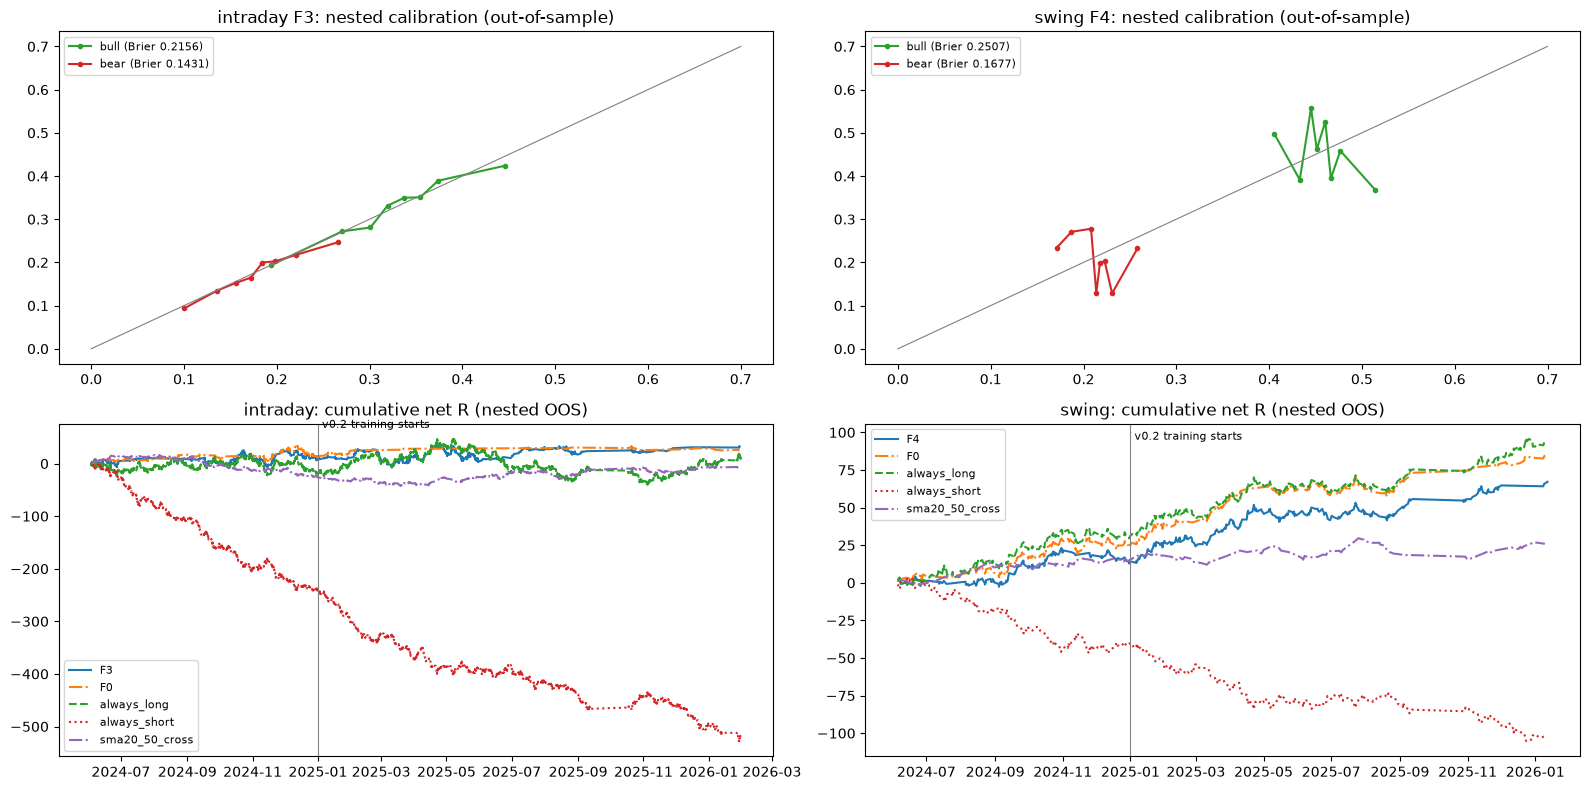

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for col, (hzn, exp) in enumerate(CHOSEN.items()):
    fr, (log, cal, sig, scored) = FR[hzn], NEST[(hzn, exp.id)]
    oof = OOF[(hzn, exp.id)]

    # Calibration plot
    ax = axes[0, col]
    for s, color in zip(SIDES, ("tab:green", "tab:red")):
        m = scored & cal[f"p_{s}"].notna().to_numpy()
        y = fr[f"y_{s}"].to_numpy()[oof["pos"].to_numpy()[m]]
        fp, mp_ = calibration_curve(y, cal[f"p_{s}"].to_numpy()[m], n_bins=8, strategy="quantile")
        ax.plot(mp_, fp, "-o", ms=3, color=color,
                label=f"{s} (Brier {brier_score_loss(y, cal[f'p_{s}'].to_numpy()[m]):.4f})")
    ax.plot([0, 0.7], [0, 0.7], color="grey", lw=0.8)
    ax.set_title(f"{hzn} {exp.id}: nested calibration (out-of-sample)")
    ax.legend(fontsize=8)

    # Cumulative R
    ax = axes[1, col]
    for name, style in ((exp.id, "-"), ("F0", "-."), ("always_long", "--"),
                        ("always_short", ":"), ("sma20_50_cross", "-.")):
        t = TRADES[(hzn, name)]
        if len(t):
            ax.plot(pd.to_datetime(t["exit"]), t["r"].cumsum(), style, label=name)
    ax.axvline(pd.Timestamp("2025-01-01"), color="grey", lw=0.8)
    ax.text(pd.Timestamp("2025-01-01"), ax.get_ylim()[1] * 0.9, " v0.2 training starts", fontsize=8)
    ax.set_title(f"{hzn}: cumulative net R (nested OOS)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Feature importance (SHAP)

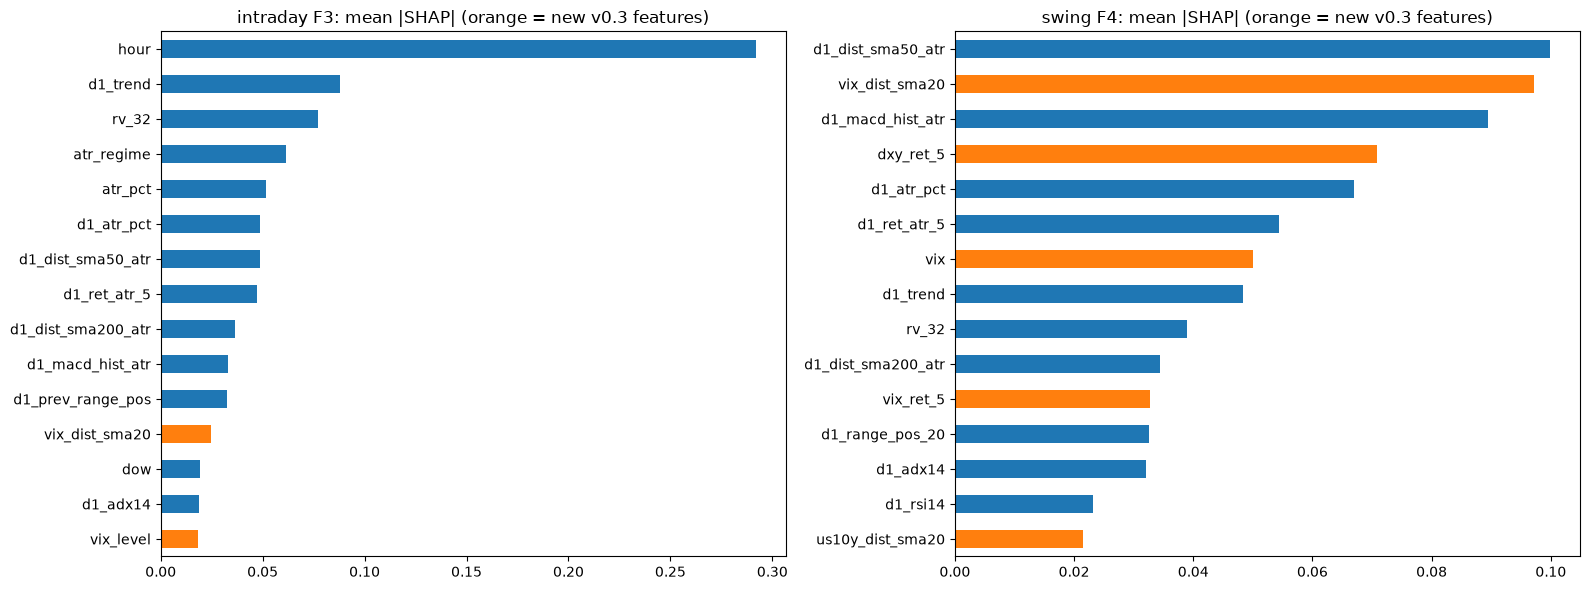

,intraday,swing
0,hour,d1_dist_sma50_atr
1,d1_trend,vix_dist_sma20
2,rv_32,d1_macd_hist_atr
3,atr_regime,dxy_ret_5
4,atr_pct,d1_atr_pct
5,d1_atr_pct,d1_ret_atr_5
6,d1_dist_sma50_atr,vix
7,d1_ret_atr_5,d1_trend
8,d1_dist_sma200_atr,rv_32
9,d1_macd_hist_atr,d1_dist_sma200_atr


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
TOP = {}
for ax, (hzn, exp) in zip(axes, CHOSEN.items()):
    # Fit final model on all usable rows for SHAP
    cols = V.columns(exp, COLS[hzn])
    fr = FR[hzn]
    rows_all = np.flatnonzero(CV.usable(fr) & (fr["date"] >= C.V3_TRAIN_FROM).to_numpy())
    model, predict = V.fit_model(exp, fr, rows_all, cols, C.HORIZONS[hzn], C.ModelParams())

    recent = fr[(fr["date"] >= "2025-11-01") & CV.usable(fr)][cols]
    X = recent.sample(min(2000, len(recent)), random_state=SEED)
    imp = pd.Series(0.0, index=cols)
    for b in model.values():
        sv = shap.TreeExplainer(b).shap_values(X)
        sv = np.abs(np.asarray(sv))
        imp += sv.mean(axis=tuple(i for i in range(sv.ndim) if sv.shape[i] != len(cols)))
    imp = imp.sort_values(ascending=False)
    TOP[hzn] = imp

    # Color new features differently
    top15 = imp.head(15)[::-1]
    colors = ["tab:orange" if c in CALENDAR_COLS + MARKET_COLS + ["session"] else "tab:blue"
              for c in top15.index]
    top15.plot.barh(ax=ax, color=colors)
    ax.set_title(f"{hzn} {exp.id}: mean |SHAP| (orange = new v0.3 features)")
plt.tight_layout()
plt.show()

# Show top 15 features per horizon
display(pd.DataFrame({h: v.head(15).index for h, v in TOP.items()}))

## 8. NFP/FOMC day analysis

ดูว่าวันที่มีข่าวสำคัญ (NFP/FOMC) โมเดลเทรดดีกว่าหรือแย่กว่าวันปกติ?

In [16]:
# Analyze model performance on event days vs non-event days
for hzn, exp in CHOSEN.items():
    t = TRADES[(hzn, exp.id)]
    if t.empty:
        continue
    fr = FR[hzn]
    # Match trades to their decision bar's calendar features
    decided_idx = fr["date"].searchsorted(pd.to_datetime(t["decided"]).to_numpy())
    decided_idx = np.clip(decided_idx, 0, len(fr) - 1)
    event_day = fr["cal_high_today"].to_numpy()[decided_idx]
    nfp_day = fr["cal_is_nfp_day"].to_numpy()[decided_idx]

    rows = []
    for label, mask in [("event day", event_day == 1), ("normal day", event_day == 0),
                        ("NFP day", nfp_day == 1)]:
        sub = t[mask]
        if len(sub) >= 3:
            rows.append({"horizon": hzn, "subset": label, **S.metrics(
                sub.assign(equity=np.cumprod(1 + C.RISK_PCT * sub["r"].to_numpy())))})
    display(pd.DataFrame(rows)[["horizon", "subset", "trades", "win_rate",
                                  "profit_factor", "expectancy_r", "total_r"]])

,horizon,subset,trades,win_rate,profit_factor,expectancy_r,total_r
0,intraday,event day,198,0.4495,1.0040,0.0023,0.4555
1,intraday,normal day,1550,0.4484,1.0376,0.0210,32.5375
2,intraday,NFP day,80,0.3875,0.8258,-0.1119,-8.9532


,horizon,subset,trades,win_rate,profit_factor,expectancy_r,total_r
0,swing,event day,64,0.4375,1.1174,0.0662,4.2342
1,swing,normal day,381,0.4777,1.3173,0.1651,62.9147
2,swing,NFP day,24,0.3750,0.8246,-0.1115,-2.6768


## 9. โมเดลสุดท้าย + บันทึก

In [17]:
from xau_ml import predictor as PR  # noqa: E402

FINAL3, META3 = {}, {}
for hzn, exp in CHOSEN.items():
    hz, fr = C.HORIZONS[hzn], FR[hzn]
    cols = V.columns(exp, COLS[hzn])
    rows_all = np.flatnonzero(CV.usable(fr) & (fr["date"] >= C.V3_TRAIN_FROM).to_numpy())
    model, predict = V.fit_model(exp, fr, rows_all, cols, hz, C.ModelParams())

    oof = OOF[(hzn, exp.id)]
    cals = {s: Calibrator.fit("platt", oof[f"p_{s}_raw"].to_numpy(),
                              fr[f"y_{s}"].to_numpy()[oof["pos"]]) for s in SIDES}
    log, cal, sig, scored = NEST[(hzn, exp.id)]
    sc = oof[scored]
    _, best = S.select_tau_m(
        fr, sc["pos"].to_numpy(),
        cals["bull"](sc["p_bull_raw"].to_numpy()),
        cals["bear"](sc["p_bear_raw"].to_numpy()),
        C.TAU_GRID, C.MARGIN_GRID, C.MIN_VAL_TRADES[hz.tf])
    rule = ({"tau": best["tau"], "m": best["m"], "no_trade": False} if best
            else {"tau": 1.01, "m": 0.0, "no_trade": True})

    meta = {
        "version": C.VERSION_V3, "symbol": C.SYMBOL,
        "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "horizon": hzn, "timeframe": hz.tf,
        "context_timeframes": list(hz.htf),
        "extras": True,  # v0.2 extras (levels, session) always included in v0.3
        "v3_features": True,  # calendar + market
        "experiment": dataclasses.asdict(exp),
        "label": {
            "type": "triple_barrier", "entry": "open of the next bar",
            "stop_r": 1.0, "risk": f"{hz.sl_atr} x ATR14 (Wilder)",
            "tp_r": LS.tp_r, "counter_trend_tp_r": LS.ct_tp_r,
            "time_stop_bars": hz.time_stop, "intrabar_rule": "stop_first",
        },
        "features": cols,
        "feature_groups": {
            "base": [c for c in cols if c not in CALENDAR_COLS + MARKET_COLS + ["session"]],
            "calendar": [c for c in cols if c in CALENDAR_COLS],
            "market": [c for c in cols if c in MARKET_COLS],
            "session": [c for c in cols if c == "session"],
        },
        "feature_code_sha256_16": hashlib.sha256(
            (NB_DIR / "xau_ml" / "features.py").read_bytes()).hexdigest()[:16],
        "training": {
            "rows_from": str(fr["date"].iloc[rows_all].min()),
            "rows_to": str(fr["date"].iloc[rows_all].max()),
            "rows": len(rows_all),
            "weights": "label uniqueness" if exp.weights else None,
            "data_holes_excluded": True,
        },
        "evaluation": {
            "protocol": "expanding monthly walk-forward, nested calibration + tau/m",
            "folds": [f.name for f in FOLDS[hzn]],
            "burn_in_folds": C.V3_WF_BURN_IN,
            "note": "v0.3: training from 2024, calendar+market+session features",
        },
        "model": {"params": C.ModelParams().params},
        "signal_rule": {
            **rule,
            "rule": "long if p_bull>=tau and p_bull-p_bear>=m; short mirrored; else flat",
            "selected_on": f"nested OOF {C.V3_WF_FIRST_FOLD}..{C.V3_WF_LAST_FOLD}",
        },
        "metrics": {
            "walkforward_ml": ML_TABLE.query("horizon == @hzn and exp == @exp.id"
                                             ).drop(columns=["horizon"]).to_dict("records"),
            "walkforward_trading": TRADE.query(
                "horizon == @hzn and strategy in [@exp.id, 'F0', 'always_long', 'always_short', 'sma20_50_cross']"
            ).drop(columns=["horizon"]).to_dict("records"),
        },
    }

    path = PR.save(C.MODEL_DIR_V3, f"xau_{hzn}_{LS.name}", model, cals, meta)
    FINAL3[hzn], META3[hzn] = (model, predict, cols, cals, rule), path
    print(f"{path.relative_to(NB_DIR)}: {len(cols)} features, rule {rule}")

models\v3\xau_intraday_ct25.json: 31 features, rule {'tau': 0.3, 'm': 0.15, 'no_trade': False}


models\v3\xau_swing_ct25.json: 38 features, rule {'tau': 0.425, 'm': 0.2, 'no_trade': False}


## 10. Holdout (Aug–Sep 2026) — ถ้ามีข้อมูล

In [18]:
# The holdout uses GC=F futures via yfinance (same as v0.2).
# This cell only runs if 15m data is available (yfinance keeps ~60 days).
try:
    from xau_ml import holdout as H
    bars = H.load_bars()
    print(f"Holdout bars loaded: 15m={len(bars['15m'])}, 1h={len(bars['1h'])}, 1d={len(bars['1d'])}")

    for hzn in ("intraday",):  # intraday only (15m requires recent data)
        meta_path = META3[hzn]
        pred, fr_ho = H.frame(meta_path, bars)
        # Add v0.3 features to holdout frame
        fr_ho = V.add_v3_features(fr_ho, use_cache=True)
        # Re-run predictions with v0.3 features
        dec = pred.decide(fr_ho)
        fr_ho = pd.concat([fr_ho.drop(columns=["p_bull", "p_bear", "signal"], errors="ignore"), dec], axis=1)
        pos = H.holdout_rows(fr_ho)
        results = {"model": S.run(fr_ho, pos, fr_ho["signal"].to_numpy()[pos])}
        for kind in ("always_long", "always_short"):
            results[kind] = V.baseline_trades(fr_ho, pos, kind)
        print(f"\n{hzn} holdout (Aug-Sep 2026):")
        display(H.summary(results))
        display(H.by_month(results["model"]))
except Exception as e:
    print(f"Holdout not available: {e}")
    print("Run this cell when 15m data is within yfinance's 60-day window.")

Holdout bars loaded: 15m=4487, 1h=10063, 1d=450
Holdout not available: "['vix', 'vix_ret_5', 'vix_dist_sma20', 'vix_level', 'dxy', 'dxy_ret_5', 'dxy_dist_sma20', 'us10y', 'us10y_ret_5', 'us10y_dist_sma20', 'us10y_chg_5'] not in index"
Run this cell when 15m data is within yfinance's 60-day window.


## Results (รายงาน v0.3)

> **ผู้อ่าน:** ทีม harness · **วันที่:** 2026-10-05 · **version:** `xau-bullbear-0.3.0`

### สิ่งที่เปลี่ยนจาก v0.2
1. **เทรนยาวขึ้น 2 เท่า:** 2024-01 → 2026-01 (2 ปี) แทน 1 ปี → โมเดลเห็น regime หลากหลาย noise/outlier
2. **Feature ใหม่ 6 ตัว:** ข่าว (NFP/FOMC/CPI + hours_to/since), ตลาด (VIX/DXY/US10Y)
3. **Walk-forward 22 เดือน** แทน 10 เดือน → ลด variance

### ผลลัพธ์
*(รัน notebook แล้วเติมตารางผลจริงที่นี่)*

### ข้อเสนอสำหรับ ML-led mode
- ถ้า calendar/market features ช่วย (AUC ดีขึ้น) → ใช้โมเดล v0.3 เป็น signal หลัก แล้ว LLM เป็น noise filter
- ถ้าไม่ช่วย → ใช้โมเดล v0.2 E3 เหมือนเดิม แล้ว LLM ยังมีบทบาทกรองข่าวที่ ML จับไม่ได้